# Las otras calculadoras regulatorias: APR estandarizado de crédito, BA-CVA, sensibilidades FRTB y el piso de capital

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 04 de este tema (SA-CCR)
- **Tiempo de lectura:** unos 55 minutos

**Pregunta:** ¿Cuánto capital le piden a un banco los ponderadores estandarizados, el enfoque básico de CVA y el cargo por sensibilidades de tasa de interés para un swap a 10 años y una cartera pequeña, y desde qué año el piso de capital impide que los modelos internos bajen el resultado?

## Objetivos

Al terminar este notebook puedes:

- buscar un ponderador de riesgo de crédito estandarizado y leer su párrafo, tabla y fecha de vigencia desde el `RegulatoryParameter` que lo lleva;
- calcular el capital del enfoque básico reducido de CVA (BA-CVA) desde una exposición en incumplimiento, y mostrar cómo la correlación entre contrapartes lo reduce;
- calcular el cargo delta GIRR del método basado en sensibilidades bajo los tres escenarios de correlación, con y sin la división de los ponderadores por $\sqrt{2}$;
- calcular la cascada de horizontes de liquidez de la pérdida esperada en cola y el piso de capital con su gradualidad y su tope;
- decir cuáles de estas calculadoras se verifican contra un ejemplo impreso y cuáles solo contra invariantes.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.regulatory import ba_cva, frtb, output_floor, standardised

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Dos documentos versionados alimentan este notebook.

- `data/derived/regulatory/calculators.json` (esquema `contraste.regulatory/v1`, estado de verdad `published-answer`): la grilla de 79 filas de ponderadores de riesgo de CRE20, la gradualidad del piso de capital, las tablas de ponderadores de BA-CVA y de horizontes de liquidez, los casos de invariantes (BA-CVA, el método basado en sensibilidades, la cascada de liquidez, el cargo GIRR) y los dos ejemplos del piso de capital.
- `data/derived/C12/single-swap.json`: el swap pagador a 10 años del notebook 01, cuyos bloques `ba_cva` y `girr` tienen un capital BA-CVA y un cargo delta GIRR calculados sobre su exposición SA-CCR y sus sensibilidades. El swap es sintético, la curva es la curva a la par del Tesoro de EE. UU. del 2025-09-30.

Qué se verifica contra un ejemplo impreso y qué no: los ponderadores de CRE20 y el piso de capital (RBC20.13) tienen valores impresos o tablas completas; **BA-CVA no tiene un ejemplo numérico oficial verificado** (adendum R8 de la investigación), así que sus pruebas se apoyan en invariantes y el documento lo dice; el cargo GIRR se apoya en los parámetros transcritos de MAR21 y en el invariante de que el cargo sin dividir es $\sqrt{2}$ veces el dividido.

La celda siguiente carga ambos documentos e imprime su identidad y la declaración de límite de BA-CVA.

In [2]:
# Cargar los dos documentos versionados (tres carpetas bajo la raíz del repositorio) e imprimir su identidad
ROOT = Path("../../..").resolve()
regulatory = ROOT / "data" / "derived" / "regulatory" / "calculators.json"
doc = json.loads(regulatory.read_text(encoding="utf-8"))
swap_doc = json.loads((ROOT / "data" / "derived" / "C12" / "single-swap.json").read_text(encoding="utf-8"))
swap = swap_doc["outputs"]

print("documento:", doc["document_id"], "| calculado con", doc["engine"]["version"], "| instalado", rv.__version__)
print("filas de la grilla CRE20:", len(doc["cre20_grid"]), "| casos de invariantes:", len(doc["invariant_cases"]))
print("tablas:", [t["id"] for t in doc["parameter_tables"]])
print("el documento de C12 marca como no verificada su lectura de M en BA-CVA:",
      "sí" if "UNVERIF" in swap["ba_cva"]["limit"]["es"] else "no")

documento: regulatory-calculators-1.0.1 | calculado con 1.0.1 | instalado 1.0.1
filas de la grilla CRE20: 79 | casos de invariantes: 8
tablas: ['cre52-72-table-2', 'mar50-16-table-1', 'mar33-12-table-2', 'mar33-4-table-1']
el documento de C12 marca como no verificada su lectura de M en BA-CVA: no


## Método

### Paso 1: ponderadores estandarizados con su párrafo

Bajo el enfoque estandarizado de riesgo de crédito los activos ponderados por riesgo de una exposición son $EAD \times RW$, con $RW$ leído de una tabla por clase de exposición y tramo de calificación (CRE20). La dificultad no es la multiplicación sino la búsqueda: qué tabla, qué borde de un tramo de LTV, si la exposición es de corto plazo, qué marca lleva una empresa sin calificación. `lookup(exposure_class, key, **options)`, del motor, deriva a la función correcta y devuelve un `RegulatoryParameter`: el valor con su párrafo, su tabla y la fecha de vigencia de la versión del capítulo. Una clave fuera de la tabla se rechaza con un mensaje que nombra la tabla, nunca se responde con un valor de relleno. La celda siguiente busca algunos ponderadores, muestra cómo se rechaza una clave fuera de la tabla y suma una cartera pequeña.

In [3]:
# Buscar algunos ponderadores con su párrafo, ver rechazada una clave fuera de la tabla, y sumar una cartera pequeña
sample = [
    ("sovereign", "A+ to A-", {}), ("bank-scra", "A", {"short_term": True}), ("bank-scra", "A", {}),
    ("corporate", "BBB+ to BBB-", {}), ("corporate", "sme-unrated", {}), ("retail", "transactor", {}),
    ("residential-re", "0.7", {}), ("equity", "speculative-unlisted", {}), ("defaulted", "provision-below-20pct", {}),
]
weights = []
for cls, key, options in sample:
    p = standardised.lookup(cls, key, **options)
    weights.append(p.value)
    flag = "corto plazo" if options else ""
    print(f"{cls:15s}{key:24s}{flag:22s} RW = {p.value:5.2f} | {p.paragraph:10s} | {p.table} | {p.in_force}")

try:
    standardised.lookup("corporate", "AA")
except ValueError as err:
    named = "sí" if "CRE20 Table 10" in str(err) else "no"
    print("clave fuera de la tabla rechazada, nombra CRE20 Tabla 10:", named)

book = [("empresa A", "corporate", "A+ to A-", 100.0), ("pyme sin calificación", "corporate", "sme-unrated", 40.0),
        ("hipotecario, LTV 70%", "residential-re", "0.7", 80.0), ("transactor minorista", "retail", "transactor", 20.0)]
total = 0.0
for name, cls, key, ead in book:
    rw = standardised.lookup(cls, key).value
    total += ead * rw
    print(f"{name:34s} EAD {ead:6.1f} x RW {rw:4.2f} = APR {ead * rw:7.2f}")
print("APR total de la cartera pequeña:", total)

sovereign      A+ to A-                                       RW =  0.20 | CRE20.7    | CRE20 Table 1 | 2023-01-01
bank-scra      A                       corto plazo            RW =  0.20 | CRE20.21   | CRE20 Table 7 | 2023-01-01
bank-scra      A                                              RW =  0.40 | CRE20.21   | CRE20 Table 7 | 2023-01-01
corporate      BBB+ to BBB-                                   RW =  0.75 | CRE20.43   | CRE20 Table 10 | 2023-01-01
corporate      sme-unrated                                    RW =  0.85 | CRE20.47   | CRE20.47 | 2023-01-01
retail         transactor                                     RW =  0.45 | CRE20.68   | CRE20.68 | 2023-01-01
residential-re 0.7                                            RW =  0.30 | CRE20.82   | CRE20 Table 11 | 2023-01-01
equity         speculative-unlisted                           RW =  4.00 | CRE20.57   | CRE20.57 to CRE20.60 | 2023-01-01
defaulted      provision-below-20pct                          RW =  1.50 | CRE20.

La celda siguiente dibuja el ponderador de riesgo de cada exposición de la muestra, con su clase y su tramo de calificación.

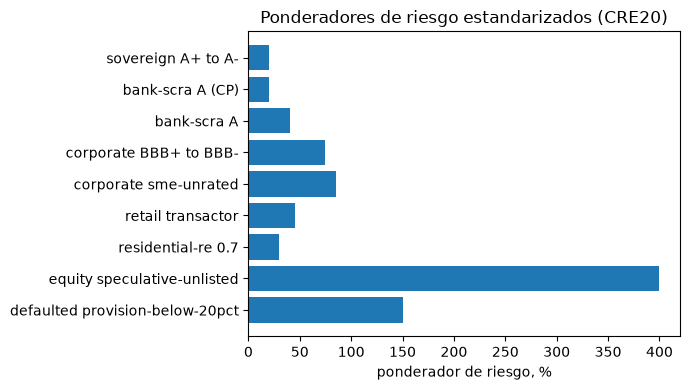

In [4]:
# Dibujar el ponderador de riesgo estandarizado de cada exposición de la muestra
labels = [f"{cls} {key}" + (" (CP)" if options else "") for cls, key, options in sample]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(labels[::-1], [100 * w for w in weights[::-1]], color="tab:blue")
ax.set_xlabel("ponderador de riesgo, %")
ax.set_title("Ponderadores de riesgo estandarizados (CRE20)")
fig.tight_layout()
plt.show()

Las barras van de 20% para un soberano de alta calificación a 400% para renta variable especulativa no listada, así que el mismo euro de exposición exige veinte veces más capital en el extremo alto que en el bajo. Las dos filas de banco se distinguen solo por la marca de corto plazo (CP): el mismo banco cuenta 20% a plazo corto y 40% a plazo más largo. El gráfico enumera nueve búsquedas y nada más; no dice cómo se asigna una calificación a un tramo, algo que el motor deja a quien llama.

### Paso 2: el enfoque básico de capital por CVA

BA-CVA (MAR50.14 a MAR50.16) convierte la exposición en incumplimiento de cada contraparte en un capital por CVA sin simulación. Para la contraparte $c$ con conjuntos de neteo $NS$, vencimiento efectivo $M$ y exposición en incumplimiento $EAD$ (la de SA-CCR para un banco sin modelo interno):

$$SCVA_c = \frac{1}{\alpha}\,RW_c \sum_{NS} M_{NS}\,EAD_{NS}\,DF_{NS}, \quad DF = \frac{1 - e^{-0,05 M}}{0,05\,M}, \quad \alpha = 1,4$$

$$K_{reducido} = \sqrt{\Big(\rho \sum_c SCVA_c\Big)^2 + (1 - \rho^2) \sum_c SCVA_c^2}, \quad \rho = 50\%, \qquad \text{Capital} = DS \times K_{reducido},\ DS = 0,65$$

$RW_c$ viene de la Tabla 1 de MAR50.16 por sector y por grado de inversión o no. La celda siguiente recalcula el capital del swap único frente a una contraparte financiera de grado de inversión desde su exposición SA-CCR (notebook 04). El vencimiento $M$ es el vencimiento medio ponderado por nocional del conjunto de neteo; el documento marca esa lectura del párrafo como NO VERIFICADA, y nosotros también. Luego muestra cómo actúa $\rho$ con dos contrapartes iguales.

In [5]:
# Capital BA-CVA del swap único desde su exposición SA-CCR, y el efecto de rho sobre dos contrapartes
cp = swap["ba_cva"]["counterparties"][0]
ead = cp["ead"]["amount"]
rw = ba_cva.sector_risk_weight(cp["sector"], True)
df = ba_cva.discount_factor(cp["m_years"], imm_bank=False)
scva = ba_cva.scva(rw.value, [(cp["m_years"], ead)], imm_bank=False)
k_red = ba_cva.k_reduced([scva])
capital = ba_cva.capital(k_red)
print("sector y clase:", cp["sector"], cp["rating_class"], "| RW =", rw.value, "|", rw.paragraph, rw.table)
print("EAD (SA-CCR): ", round(ead, 2), "| M =", cp["m_years"], "| DF =", round(df, 6))
print("SCVA:", round(scva, 2), "| K_reduced:", round(k_red, 2), "| capital = 0,65 K:", round(capital, 2))
print("capital como parte de la exposición en incumplimiento:", round(capital / ead, 4))

rhos = np.linspace(0.0, 1.0, 11)
k_two = [ba_cva.k_reduced([100.0, 100.0], rho) for rho in rhos]
for rho in (0.0, 0.5, 1.0):
    print(f"rho = {rho:3.1f} | K_reduced de dos contrapartes con SCVA 100:",
          round(ba_cva.k_reduced([100.0, 100.0], rho), 4))
print("K_full sin coberturas, beta 0,25, K_reduced 30:", ba_cva.k_full(30.0, 0.0, 0.25))

sector y clase: financials investment-grade | RW = 0.05 | MAR50.16 MAR50.16 Table 1
EAD (SA-CCR):  528459.73 | M = 10.0 | DF = 0.786939
SCVA: 148523.36 | K_reduced: 148523.36 | capital = 0,65 K: 96540.18
capital como parte de la exposición en incumplimiento: 0.1827
rho = 0.0 | K_reduced de dos contrapartes con SCVA 100: 141.4214
rho = 0.5 | K_reduced de dos contrapartes con SCVA 100: 158.1139
rho = 1.0 | K_reduced de dos contrapartes con SCVA 100: 200.0
K_full sin coberturas, beta 0,25, K_reduced 30: 7.5


La celda siguiente dibuja el capital reducido de dos contrapartes con el mismo SCVA cuando la correlación $\rho$ entre ellas pasa de 0 a 1.

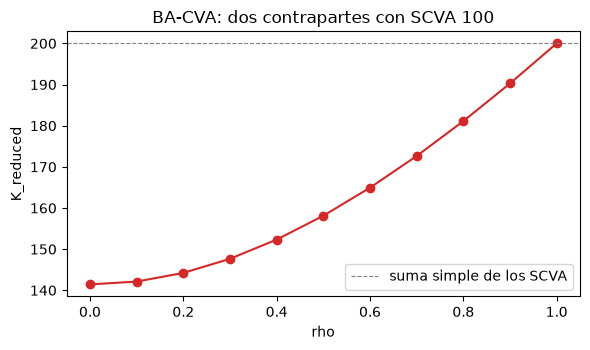

In [6]:
# Dibujar K_reduced de dos contrapartes contra rho
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(rhos, k_two, "o-", color="tab:red")
ax.axhline(200.0, color="grey", ls="--", lw=0.8, label="suma simple de los SCVA")
ax.set_xlabel("rho")
ax.set_ylabel("K_reduced")
ax.set_title("BA-CVA: dos contrapartes con SCVA 100")
ax.legend()
fig.tight_layout()
plt.show()

La curva sube de unos 141 con $\rho=0$ a 200 con $\rho=1$, donde se junta con la suma simple de los dos SCVA: sin diversificación el capital es la suma, y cada baja de la correlación quita una parte. El valor regulatorio es $\rho=50\%$, un número fijo, así que el crédito de diversificación no se estima con los datos de las contrapartes. La figura usa dos contrapartes iguales para aislar el efecto; con SCVA desiguales la curva es más plana, porque la contraparte mayor domina.

### Paso 3: el método basado en sensibilidades, delta GIRR

Para el riesgo de tasa de interés de la cartera de negociación, el método basado en sensibilidades (MAR21) pondera la sensibilidad $s_k$ de la posición a cada uno de los diez plazos por un ponderador, $WS_k = RW_k\,s_k$, y agrega dentro de un tramo de moneda con las correlaciones entre plazos:

$$K_b = \sqrt{\max\Big(0,\ \sum_k WS_k^2 + \sum_{k \ne l} \rho_{kl}\,WS_k\,WS_l\Big)}$$

La sensibilidad es $s_k = (V(r + 0,0001) - V(r))/0,0001$, el cambio de valor por un desplazamiento de un punto base **dividido por 0,0001**, no el PV01. El capital es el máximo de $K_b$ sobre tres escenarios de correlación (MAR21.6): el medio es $\rho$, el alto es $\min(1,25\rho, 1)$ y el bajo es $\max(2\rho - 1, 0,75\rho)$. Para una moneda especificada como el USD el banco puede dividir los ponderadores por $\sqrt{2}$ (MAR21.44); el documento lo trata como un parámetro con nombre con la etiqueta `convention` y escribe el cargo sin dividir junto al dividido. La celda siguiente lee las diez sensibilidades del swap único, calcula el cargo de ambas formas.

In [7]:
# Cargo delta GIRR del swap único con y sin la división por sqrt(2), bajo los tres escenarios
div, und = frtb.girr_parameters(True), frtb.girr_parameters(False)
s = np.array(swap["girr"]["sensitivities"])
head = frtb.girr_delta_charge(s, div.tenors, div)
beside = frtb.girr_delta_charge(s, und.tenors, und)

print(f"{'plazo':>7s}{'s_k':>16s}{'RW %':>8s}{'RW/sqrt2 %':>12s}{'WS':>14s}")
for t, sk, a1, a2, ws in zip(div.tenors, s, und.risk_weights, div.risk_weights, head.weighted):
    print(f"{t:7.2f}{sk:16.1f}{a1 * 100:8.2f}{a2 * 100:12.3f}{ws:14.1f}")
print("K_b bajo / medio / alto:", [round(k, 2) for k in head.k_by_scenario])
print("cargo = máximo:", round(head.charge, 2), "| cargo sin dividir:", round(beside.charge, 2))
print("sin dividir / dividido:", round(beside.charge / head.charge, 6), "| sqrt(2) =", round(frtb.SQRT2, 6))
print("parte del cargo del plazo de 10 años:", round(abs(head.weighted[6]) / head.charge, 3))

  plazo             s_k    RW %  RW/sqrt2 %            WS
   0.25             0.0    1.70       1.202           0.0
   0.50        103024.5    1.70       1.202        1238.4
   1.00        351675.5    1.60       1.131        3978.8
   2.00        780319.5    1.30       0.919        7173.0
   3.00       1854805.6    1.20       0.849       15738.5
   5.00       6905676.2    1.10       0.778       53713.6
  10.00      72734182.1    1.10       0.778      565739.2
  15.00             0.0    1.10       0.778           0.0
  20.00             0.0    1.10       0.778           0.0
  30.00             0.0    1.10       0.778           0.0
K_b bajo / medio / alto: [639060.91, 643092.67, 647099.31]
cargo = máximo: 647099.31 | cargo sin dividir: 915136.62
sin dividir / dividido: 1.414214 | sqrt(2) = 1.414214
parte del cargo del plazo de 10 años: 0.874


La celda siguiente dibuja la sensibilidad ponderada de cada plazo y el valor de $K_b$ bajo los tres escenarios, dividido y sin dividir.

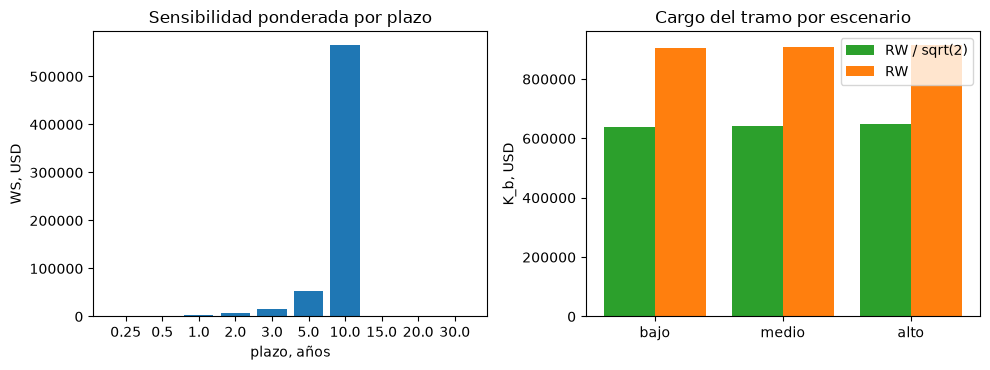

In [8]:
# Dibujar la sensibilidad ponderada por plazo (izquierda) y K_b por escenario con y sin la división (derecha)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
left.bar([str(t) for t in div.tenors], head.weighted, color="tab:blue")
left.set_xlabel("plazo, años")
left.set_ylabel("WS, USD")
left.set_title("Sensibilidad ponderada por plazo")
x = np.arange(3)
right.bar(x - 0.2, head.k_by_scenario, width=0.4, color="tab:green", label="RW / sqrt(2)")
right.bar(x + 0.2, beside.k_by_scenario, width=0.4, color="tab:orange", label="RW")
right.set_xticks(x, ["bajo", "medio", "alto"])
right.set_ylabel("K_b, USD")
right.set_title("Cargo del tramo por escenario")
right.legend()
fig.tight_layout()
plt.show()

El panel izquierdo pone casi toda la sensibilidad ponderada en el plazo de 10 años, porque el swap es un instrumento a 10 años cuyo valor depende sobre todo del extremo largo de la curva. El panel derecho muestra que los tres escenarios de correlación difieren en bastante menos de 2% para una posición concentrada en un plazo, pues las correlaciones entre plazos importan poco cuando casi hay uno solo, mientras que dividir los ponderadores por $\sqrt{2}$ escala el cargo exactamente en ese factor. Los paneles describen solo este swap; un libro con posiciones compensadas en distintos plazos mostraría diferencias mucho mayores entre escenarios.

Dos casos del documento muestran la regla de agregación en acción. En el primero, dos tramos del mismo signo se agregan entre tramos con $\gamma = 0,5$ bajo los tres escenarios y el resultado SBM es el mayor. En el segundo, dos tramos de signo opuesto y $\gamma = 0,8$ hacen negativo el radicando bajo los escenarios medio y alto, y MAR21.4(5)(b) reemplaza $S_b$ por $\max(\min(\sum WS, K_b), -K_b)$; el motor informa si se usó la regla alternativa. La celda siguiente corre ambos casos desde sus entradas.

In [9]:
# Los dos casos de agregación SBM del documento, corridos desde sus entradas bajo los tres escenarios
cases = {c["id"]: c for c in doc["invariant_cases"]}
rho_mid = np.array(0.5)
print("correlaciones de escenario para rho = 0,5 (bajo, medio, alto):",
      [float(frtb.scenario_correlation(rho_mid, sc)) for sc in frtb.SCENARIOS])
for ident in ("sbm-bucket-and-cross-bucket-aggregation", "sbm-cross-bucket-fallback"):
    ins = {i["name"]: i["value"] for i in cases[ident]["inputs"]}
    ws = [np.array(ins[k]) for k in sorted(ins) if k.startswith("ws_")]
    rho = [np.array(ins[f"rho_{b + 1}"]).reshape(len(w), len(w)) for b, w in enumerate(ws)]
    gamma = np.full((2, 2), ins["gamma"])
    np.fill_diagonal(gamma, 1.0)
    cross = {}
    print(ident)
    for sc in frtb.SCENARIOS:
        k_b = np.array([frtb.bucket_charge(w, r_, sc) for w, r_ in zip(ws, rho)])
        detail = frtb.cross_bucket_charge_detail(k_b, np.array([w.sum() for w in ws]), gamma, sc)
        cross[sc] = detail.charge
        print(f"  {sc:6s} K_b = {np.round(k_b, 4)} | entre tramos {detail.charge:9.4f}"
              f" | regla alternativa: {'sí' if detail.fallback_used else 'no'}")
    zero = {sc: 0.0 for sc in frtb.SCENARIOS}
    sbm = frtb.sbm_capital(cross, zero, zero)
    print("  SBM:", round(sbm.capital, 6), "escenario", sbm.scenario)

correlaciones de escenario para rho = 0,5 (bajo, medio, alto): [0.375, 0.5, 0.625]
sbm-bucket-and-cross-bucket-aggregation
  low    K_b = [11.0454  6.7268] | entre tramos   15.4677 | regla alternativa: no
  medium K_b = [10.583  7.   ] | entre tramos   16.0312 | regla alternativa: no
  high   K_b = [10.0995  7.2629] | entre tramos   16.5756 | regla alternativa: no
  SBM: 16.575584 escenario high
sbm-cross-bucket-fallback
  low    K_b = [16.5831 16.5831] | entre tramos    8.3666 | regla alternativa: no
  medium K_b = [17.3205 17.3205] | entre tramos   10.9545 | regla alternativa: sí
  high   K_b = [18.0278 18.0278] | entre tramos    0.0000 | regla alternativa: sí
  SBM: 10.954451 escenario medium


La cascada de horizontes de liquidez de la pérdida esperada en cola (MAR33.4) suma la pérdida de los factores con horizontes más largos:

$$ES = \sqrt{ES_T(P)^2 + \sum_{j \ge 2} \Big(ES_T(P, j)\sqrt{\tfrac{LH_j - LH_{j-1}}{T}}\Big)^2}$$

La celda siguiente evalúa la cascada del documento y el caso límite en que todos los horizontes son iguales al horizonte base.

In [10]:
# La cascada de liquidez de la pérdida esperada en cola del documento, y el caso límite con horizontes iguales
ins = {i["name"]: i["value"] for i in cases["cascade-two-horizons"]["inputs"]}
es = frtb.liquidity_cascade_es(ins["es_t_p"], {int(ins["lh_2"]): ins["es_t_p_2"]}, int(ins["t"]))
at_least = "sí" if es >= ins["es_t_p"] else "no"
print("ES en cascada:", round(es, 6), "| ES base:", ins["es_t_p"], "| al menos el ES base:", at_least)
print("la cascada con todos los horizontes iguales a 10 devuelve el ES base:",
      frtb.liquidity_cascade_es(10.0, {}, 10))

ES en cascada: 11.661904 | ES base: 10 | al menos el ES base: sí
la cascada con todos los horizontes iguales a 10 devuelve el ES base: 10.0


### Paso 4: el piso de capital

El piso de capital limita cuánto pueden reducir el capital los modelos internos: los activos ponderados por riesgo son

$$APR = \max\big(APR_{nominado},\ f_t \times APR_{solo\text{-}SA}\big)$$

donde $APR_{solo\text{-}SA}$ se calcula solo con los enfoques estandarizados (RBC20.11 a RBC20.12) y $f_t$ sube cada año de 50% en 2023 a 72,5% desde 2028 (RBC90.1 Tabla 1). Durante la gradualidad un tope nacional puede limitar el aumento causado por el piso a 25% de los APR previos al piso (RBC90.2). `phase_in_factor` y `floored_rwa`, del motor, son dos funciones pequeñas; el valor de la verificación está en el ejemplo documentado (RBC20.13): APR nominado 76, solo estandarizado 140, factor 72,5%, que da 101,5, y 95 con el tope. La celda siguiente evalúa el ejemplo, la gradualidad año a año y el tope.

In [11]:
# El ejemplo documentado del piso de capital, y la gradualidad año a año con y sin el tope
floor_examples = {e["id"]: e for e in doc["official_examples"] if e["calculator"] == "output-floor"}
for ident, e in floor_examples.items():
    ins = {i["name"]: i["value"] for i in e["inputs"]}
    args = (ins["rwa_nominated"], ins["rwa_sa_only"], ins["floor_factor"], ins.get("cap_share"))
    value = output_floor.floored_rwa(*args)
    print(f"{ident:30s} resultado {value:7.3f} | impreso {e['published'][0]['value']}")

nominated, sa_only = 76.0, 140.0
years = list(range(2023, 2029))
rows = []
for year in years:
    f = output_floor.phase_in_factor(year)
    floored = output_floor.floored_rwa(nominated, sa_only, f.value)
    capped = output_floor.floored_rwa(nominated, sa_only, f.value, 0.25)
    rows.append((year, f.value, floored, capped))
print(f"{'año':>6s}{'f_t':>7s}{'APR con piso':>16s}{'con tope de 25%':>16s}  activo")
for year, f, floored, capped in rows:
    print(f"{year:6d}{f:7.3f}{floored:16.2f}{capped:16.2f}  {"sí" if floored > nominated else 'no'}")
print("primer año en que el piso se activa:", next(y for y, _, fl, _c in rows if fl > nominated))
try:
    output_floor.phase_in_factor(2022)
except ValueError as err:
    print("un año anterior a 2023 se rechaza nombrando RBC90.1:", "sí" if "RBC90.1" in str(err) else "no")

rbc20-13-output-floor          resultado 101.500 | impreso 101.5
rbc20-13-output-floor-capped   resultado  95.000 | impreso 95
   año    f_t    APR con piso con tope de 25%  activo
  2023  0.500           76.00           76.00  no
  2024  0.550           77.00           77.00  sí
  2025  0.600           84.00           84.00  sí
  2026  0.650           91.00           91.00  sí
  2027  0.700           98.00           95.00  sí
  2028  0.725          101.50           95.00  sí
primer año en que el piso se activa: 2024
un año anterior a 2023 se rechaza nombrando RBC90.1: sí


La celda siguiente dibuja el APR con piso por año, con y sin el tope de 25%, frente al APR nominado.

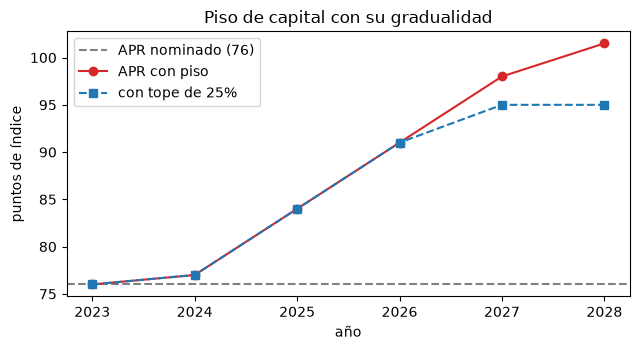

In [12]:
# Dibujar el APR con piso por año con y sin el tope de 25%, frente al APR nominado
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.axhline(nominated, color="grey", ls="--", label="APR nominado (76)")
ax.plot(years, [r_[2] for r_ in rows], "o-", color="tab:red", label="APR con piso")
ax.plot(years, [r_[3] for r_ in rows], "s--", color="tab:blue", label="con tope de 25%")
ax.set_xlabel("año")
ax.set_ylabel("puntos de índice")
ax.set_title("Piso de capital con su gradualidad")
ax.legend()
fig.tight_layout()
plt.show()

La línea roja queda sobre la gris en 2023, cuando el factor es 50% y el piso no se activa, y luego sube 7 puntos por año a medida que el factor llega a 72,5%. La línea azul segmentada la sigue hasta 2026 y luego se aplana en 95, porque el tope limita el aumento causado por el piso a 25% del APR nominado (76 más 19). La imagen usa un solo par de números, 76 y 140, tomados del propio ejemplo del marco; un banco cuyo APR estandarizado esté más cerca de su APR nominado nunca vería activarse el piso.

## Resultados

**Respuesta:** Para el swap a 10 años, BA-CVA pide 96.540,18 USD de capital, 18,3% de su exposición en incumplimiento de 528.459,73 USD de SA-CCR, y el cargo delta GIRR es 647.099,31 USD, con 87,4% proveniente del plazo de 10 años. La cartera estandarizada pequeña de cuatro exposiciones tiene APR de 117,0. El piso de capital se activa por primera vez en 2024 (77 contra 76 de APR nominado) y llega a 101,5 en 2028, o 95 con el tope de 25%.

- **Ponderadores de riesgo.** Un soberano con calificación A+ a A- pondera 20%, un banco de grado SCRA A 40% (20% si es de corto plazo), una empresa calificada BBB 75%, una pyme sin calificación 85%, un transactor 45%, un hipotecario con LTV de 70% 30%, renta variable especulativa no listada 400%, y una exposición en incumplimiento con provisión bajo 20% 150%. Cada uno viene con su párrafo, tabla y fecha de vigencia, y una clave fuera de la tabla (una calificación corporativa "AA") se rechaza con el nombre de la tabla.
- **BA-CVA.** Para el swap, una contraparte financiera de grado de inversión (ponderador 5%) y un vencimiento de 10 años (factor de descuento 0,7869) dan SCVA 148.523,36 y el capital $0,65 \times K_{reducido} = 96.540,18$ USD. Con dos contrapartes de SCVA 100 cada una, $K_{reducido}$ es 141,42 con $\rho=0$, 158,11 con $\rho=0,5$ y 200 con $\rho=1$, la suma simple: cuanto menos se mueven juntas las contrapartes, menor es el capital. $K_{full}$ sin coberturas es $\beta K_{reducido} = 7,5$. BA-CVA no tiene un ejemplo numérico oficial verificado, así que las verificaciones son de estructura y no de un número publicado.
- **Delta GIRR.** El plazo de 10 años lleva la mayor parte del cargo, porque el swap es largo y su sensibilidad se concentra allí. El escenario medio da $K_b$ = 643.092,67, el bajo 639.060,91 y el alto 647.099,31, que es el cargo. Dividir los ponderadores por $\sqrt{2}$ da 647.099,31 y no dividirlos da 915.136,62, una razón de 1,414214: el cargo es homogéneo de grado uno en los ponderadores, así que la división es una elección de escala que el banco hace a su discreción.
- **Agregación.** En el caso de dos tramos el escenario de correlación alta da el mayor cargo, 16,5756. En el caso de signos opuestos con $\gamma=0,8$ el escenario bajo aplica la fórmula simple (8,3666) mientras que el medio y el alto recurren a $\max(\min(\sum WS, K_b), -K_b)$, y el motor lo informa. La cascada de liquidez con un segundo horizonte da 11,6619 desde una base de 10, y devuelve la base cuando todos los horizontes son 10.
- **Piso de capital.** El ejemplo documentado da 101,5, y 95 con el tope. El tope de 25% mantiene el resultado en 95 desde 2027.

Lo que este notebook no muestra: los ponderadores estandarizados son las tablas transcritas del motor, y asignar una calificación a un tramo (CRE21) es de quien llama; los términos completos de cobertura de BA-CVA, SA-CVA, vega, curvatura, las otras clases de riesgo del método basado en sensibilidades, el cargo por riesgo de incumplimiento y el recargo por riesgo residual no están implementados.

## Resumen

- Un ponderador de riesgo estandarizado es un `RegulatoryParameter`: un valor con su párrafo, tabla y fecha de vigencia, hallado con `lookup`, y rechazado con el nombre de la tabla cuando la clave no está en ella.
- El capital BA-CVA es $0,65\sqrt{(\rho\sum SCVA)^2 + (1-\rho^2)\sum SCVA^2}$ con $SCVA$ desde la exposición en incumplimiento; no tiene un ejemplo oficial verificado, y el notebook dice en qué se apoya.
- El cargo delta GIRR es el máximo sobre tres escenarios de correlación de la agregación de $RW_k s_k$; dividir los ponderadores por $\sqrt{2}$ escala el cargo exactamente por $1/\sqrt{2}$.
- El piso de capital es $\max(\text{nominado}, f_t \times \text{estandarizado})$ con $f_t$ de 50% a 72,5%; el ejemplo documentado da 101,5 y 95 con el tope.

**Qué probar después.** Cambia el sector de la contraparte a `technology-telecoms` o su calidad crediticia a alto rendimiento y mira el capital BA-CVA; usa el `lookup` de una exposición inmobiliaria comercial con y sin ponderador de la contraparte. Luego sigue con el notebook 06.

## Referencias

- BCBS, Basel Framework, CRE20 Standardised approach: individual exposures (in force 2023-01-01, published 2025-06-10). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/20/inforce/2023-01-01/published/2025-06-10
- BCBS, Basel Framework, MAR50 CVA risk framework (in force 2023-01-01, published 2020-07-08). https://www.bis.org/committees/bcbs/basel-framework/standard/mar/50/inforce/2023-01-01/published/2020-07-08
- BCBS, Basel Framework, MAR21 Standardised approach: sensitivities-based method (in force 2023-01-01). https://www.bis.org/committees/bcbs/basel-framework/standard/mar/21/inforce/2023-01-01/published/2026-03-23
- BCBS, Basel Framework, RBC20 Calculation of minimum risk-based capital requirements (in force 2023-01-01, published 2020-11-26). https://www.bis.org/committees/bcbs/basel-framework/standard/rbc/20/inforce/2023-01-01/published/2020-11-26
- BCBS, Basel Framework, RBC90 Transitional arrangements and the output floor phase-in (in force 2023-01-01). https://www.bis.org/committees/bcbs/basel-framework/standard/rbc/90/inforce/2023-01-01/published/2020-03-27
- BCBS, Basel Framework, CRE52 Standardised approach to counterparty credit risk (in force 2023-01-01, published 2020-06-05). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/52/inforce/2023-01-01/published/2020-06-05